# Learner flexibility and selection bias

A spline term can be selected more often than its effect warrants when it is
more flexible than competing terms. This can occur even when its predictor
has no effect.

The reason is in how each iteration chooses a term. A base learner is the
simple regression model attached to one term, such as a straight line or a
penalized spline. At each iteration every base learner is fitted to the part of
the response the model has not accounted for yet, and the
learner that reduces what remains by the most is the one added to the model. A
spline with four free parameters reduces it further than a straight line with
one, whatever it is fitted to, so a term can be selected for its flexibility
rather than for its effect. The general form of the quantity each learner is
fitted to is derived in [](../methodology/functional_gradient_boosting.ipynb).

This study fits data whose true effects are known, so the term that should have
been selected is known too, and measures how three ways of writing the same
predictors change which one is credited.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | whether giving one term more flexibility makes it win selection on that account alone |
| **Observed response** | a simulated continuous outcome |
| **Estimand** | the selection frequency of each term — including a term with no effect at all |
| **Units** | simulated, arbitrary scale |
| **Sampling unit** | one simulated observation |
| **Dependence** | independent by construction |
| **Split / resampling unit** | the observation |
| **Tuning** | `mstop` by cross-validated risk |
| **Uncertainty** | repeated simulation, so the frequencies carry their own Monte Carlo spread |
| **Claim type** | methodological, on data whose truth is set by the simulation |
:::


## The data

The data are simulated, 200 observations per data set. Three predictors are
drawn uniformly on $[-2, 2]$, and the response is

$$ y = x_1 + x_2 + \varepsilon, \qquad \varepsilon \sim N(0, 1). $$

`x3` enters no part of the response. Its true effect is zero over the whole
range, so any fitted structure in `x3` is an error whose size can be measured.

In [1]:
import collections
import warnings

import numpy as np
import polars as pl

import mboostrs as mb

n_obs = 200


def simulate(rng, rows=n_obs):
    # x1 and x2 have unit linear effects; x3 has none.
    data = {name: rng.uniform(-2, 2, rows) for name in ("x1", "x2", "x3")}
    data["y"] = data["x1"] + data["x2"] + rng.normal(0, 1.0, rows)
    return data


rng = np.random.default_rng(11)
example = simulate(rng)
print(f"n = {n_obs}, true effects: x1 slope 1, x2 slope 1, x3 none")
print(f"response sd {example['y'].std(ddof=1):.2f}, noise sd 1.00")

n = 200, true effects: x1 slope 1, x2 slope 1, x3 none
response sd 2.05, noise sd 1.00


## Three specifications with unequal and equal degrees of freedom

`bbs(x, df=4)` is a P-spline learner: a cubic B-spline basis in `x` (24
columns) whose coefficients are fitted with a ridge penalty, $\lambda$ times the
sum of squared second differences of neighbouring coefficients. Its degrees of freedom
are the effective number of parameters of that penalized fit, the trace of the
matrix that maps the data to the fitted values, and $\lambda$ is chosen so that
this trace equals the requested `df`. `bols(x)` fits an intercept and a slope
without a penalty, so its trace is 2. Both learners contain the constant, and
under the Gaussian loss the residuals they are fitted to have mean zero, so the
constant part fits nothing: the straight line competes with one effective
parameter, the slope, and `bbs(x, df=4)` with three. The derivation of the
degrees of freedom is in [](../methodology/penalties_df.ipynb).

**Unequal.** The two true effects enter as straight lines and the noise
predictor as a P-spline: `bols(x1) + bols(x2) + bbs(x3, df=4)`. A
specification takes this form when the predictor whose shape is uncertain gets
a spline and the others keep straight lines.

**Equal.** All three enter as `bbs(x, df=4)`.

**Decomposed.** Each predictor enters twice: as `bols(x)`, one degree of
freedom, and as `bbs(x, center=True, df=1)`, the deviation from that straight
line with the constant and linear parts removed, with one degree of freedom.
Every learner in the model then competes with one effective parameter, and the
choice between a straight effect and a curved one is made among equals.

In [2]:
specifications = {
    "unequal": "y ~ bols(x1) + bols(x2) + bbs(x3, df=4)",
    "equal": "y ~ bbs(x1, df=4) + bbs(x2, df=4) + bbs(x3, df=4)",
    "decomposed": ("y ~ bols(x1) + bols(x2) + bols(x3) + "
                   "bbs(x1, center=True, df=1) + bbs(x2, center=True, df=1) + "
                   "bbs(x3, center=True, df=1)"),
}

def fitted_swing(model, source, name):
    # Range of the fitted prediction as one predictor moves across the values
    # it takes in the data, with the others held at zero. The true swing is 4
    # for x1 and x2 and 0 for x3.
    grid = {v: np.zeros(60) for v in ("x1", "x2", "x3")}
    grid[name] = np.linspace(source[name].min(), source[name].max(), 60)
    return float(np.ptp(np.asarray(model.predict(newdata=grid)).ravel()))

folds = mb.cv_weights(n_obs, type="kfold", B=10, seed=1)

rows = []


In [3]:
for label, formula in specifications.items():
    model = mb.gamboost(formula, data=example, family=mb.Gaussian(),
                        control=mb.boost_control(400, 0.1))
    stop = model.cvrisk(folds=folds).optimal_mstop
    stopped = model[:stop]
    steps = collections.Counter(list(model.selected)[:stop])
    rows.append({
        "specification": label,
        "mstop": stop,
        "steps on x1": steps.get("x1", 0),
        "steps on x2": steps.get("x2", 0),
        "steps on x3": steps.get("x3", 0),
        "x3 share": round(steps.get("x3", 0) / stop, 3),
        "fitted swing in x3": round(fitted_swing(stopped, example, "x3"), 3),
    })

display(pl.DataFrame(rows))


specification,mstop,steps on x1,steps on x2,steps on x3,x3 share,fitted swing in x3
str,i64,i64,i64,i64,f64,f64
"""unequal""",71,25,26,20,0.282,0.409
"""equal""",71,28,26,17,0.239,0.374
"""decomposed""",55,23,24,8,0.145,0.107


Under the unequal specification the noise predictor takes 20 of the 71
iterations, 28.2% of them, and its fitted effect moves 0.409 across the range
of `x3` where the truth is flat. Under the decomposed specification it takes 8
of 55 iterations, 14.5%, and moves 0.107.

The mechanism is the step-by-step comparison. A `bbs(x3, df=4)` learner has
three effective parameters to fit the current residual; the `bols(x1)` learner
competing with it has one. When the remaining signal in `x1` is small, three
parameters fitted to noise leave a smaller residual sum of squares than one
parameter fitted to a weak effect.

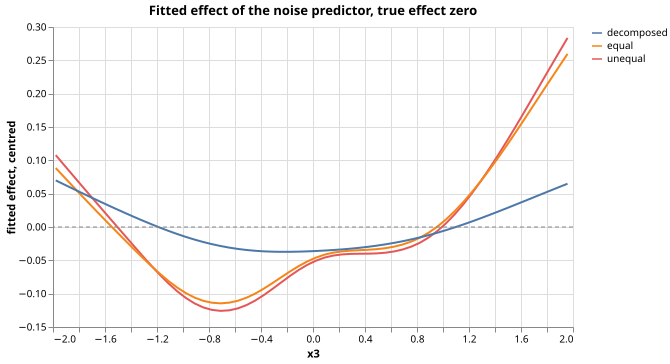

In [4]:
curves = []
for label, formula in specifications.items():
    model = mb.gamboost(formula, data=example, family=mb.Gaussian(),
                        control=mb.boost_control(400, 0.1))
    stopped = model[:model.cvrisk(folds=folds).optimal_mstop]
    grid = {v: np.zeros(60) for v in ("x1", "x2", "x3")}
    grid["x3"] = np.linspace(example["x3"].min(), example["x3"].max(), 60)
    predicted = np.asarray(stopped.predict(newdata=grid)).ravel()
    curves.append(pl.DataFrame({
        "x3": grid["x3"],
        "effect": predicted - predicted.mean(),
        "specification": [label] * 60,
    }))
# Reuse the declared folds so comparisons differ by model, not by split.
import altair as alt

curve_frame = pl.concat(curves)
truth = alt.Chart(pl.DataFrame({"effect": [0.0]})).mark_rule(
    color="#888888", strokeDash=[4, 3]
).encode(y="effect:Q")
lines = alt.Chart(curve_frame).mark_line(strokeWidth=2).encode(
    x=alt.X("x3:Q", title="x3"),
    y=alt.Y("effect:Q", title="fitted effect, centred"),
    color=alt.Color("specification:N", title=None),
)
alt.layer(lines, truth).properties(
    title="Fitted effect of the noise predictor, true effect zero",
    width=520, height=300,
)


## Results over twenty replicates

One data set fixes one draw of the noise. The three specifications are refitted
on twenty fresh data sets, each with its own fold assignment, and each is
evaluated against the true function $x_1 + x_2$ on 2000 fresh observations.

In [5]:
rng = np.random.default_rng(11)
replicates = []
for replicate in range(20):
    training = simulate(rng)
    holdout = simulate(rng, rows=2000)
    truth_holdout = holdout["x1"] + holdout["x2"]
    replicate_folds = mb.cv_weights(n_obs, type="kfold", B=10, seed=replicate + 1)
    for label, formula in specifications.items():
        model = mb.gamboost(formula, data=training, family=mb.Gaussian(),
                            control=mb.boost_control(400, 0.1))
        stop = model.cvrisk(folds=replicate_folds).optimal_mstop
        steps = collections.Counter(list(model.selected)[:stop])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", UserWarning)
            predicted = np.asarray(model[:stop].predict(newdata=holdout)).ravel()
        replicates.append({
            "specification": label,
            "x3 share": steps.get("x3", 0) / stop,
            "x3 selected": steps.get("x3", 0) > 0,
            "error against the truth": float(np.mean((truth_holdout - predicted) ** 2)),
        })
# Reuse the declared folds so comparisons differ by model, not by split.
replicate_summary = (
    pl.DataFrame(replicates)
    .group_by("specification")
    .agg(
        pl.col("x3 share").mean().round(3).alias("mean share of steps on x3"),
        pl.col("x3 selected").mean().alias("runs selecting x3"),
        pl.col("error against the truth").mean().round(3).alias("error against the truth"),
    )
    .sort("mean share of steps on x3", descending=True)
)
display(replicate_summary)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 400 is within 5% of the search cap 400; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/tmp/ipykernel_67401/3973281325.py:11: RuntimeWarning: the cross-validated risk is still falling at mstop=400, the largest iteration evaluated, so the reported optimal_mstop=400 is where the path stopped rather than where the risk turns. Refit with a larger mstop and cross-validate again on the same folds: `model.continue_to(800)` then `cvrisk(folds=...)`. (`continue_to` resumes the retained gradient where the fit kept one, and otherwise costs a full path; `parity_notes(include_global=True)` says which routes resume.)
  stop = model.cvrisk(folds=replicate_folds).optimal_mstop
/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 400 is within 5% of the search cap 400; the search range was exhaust

specification,mean share of steps on x3,runs selecting x3,error against the truth
str,f64,f64,f64
"""unequal""",0.22,0.85,0.023
"""equal""",0.092,0.65,0.041
"""decomposed""",0.068,0.45,0.025


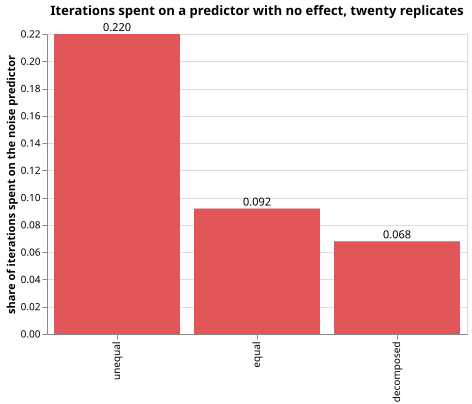

In [6]:
shares = replicate_summary.select("specification", "mean share of steps on x3")
bars = alt.Chart(shares).mark_bar(color="#e15759").encode(
    x=alt.X("specification:N", title=None, sort="-y"),
    y=alt.Y("mean share of steps on x3:Q", title="share of iterations spent on the noise predictor"),
)
labels = alt.Chart(shares).mark_text(dy=-6, fontSize=11).encode(
    x=alt.X("specification:N", sort="-y"),
    y=alt.Y("mean share of steps on x3:Q"),
    text=alt.Text("mean share of steps on x3:Q", format=".3f"),
)
alt.layer(bars, labels).properties(
    title="Iterations spent on a predictor with no effect, twenty replicates",
    width=420, height=300,
)

Across the twenty replicates the noise predictor takes 22.0% of the iterations
under the unequal specification, 9.2% under equal degrees of freedom, and 6.8%
under the decomposition. It is selected at least once in 85%, 65% and 45% of
the runs.

The error against the true function is the mean squared difference between
the fitted prediction and $x_1 + x_2$ over the 2000 fresh observations, in
squared response units; lower is better. It runs the other way for the equal
specification: 0.023 unequal, 0.041 equal, 0.025 decomposed. Fitting a straight
truth with a `df=4` spline spends three effective parameters where one would do,
and the extra estimation error costs more than the selection error the equal
specification removes. The decomposition avoids both, because the straight part
of each effect is fitted by a one-parameter learner and only the deviation from
it competes on spline terms.

## Conclusions

A base learner with more degrees of freedom is selected more often than its
effect warrants. A predictor with no effect took 22.0% of the iterations when
it was the only spline term among straight-line competitors, against 6.8% when
every learner competed with one effective parameter.

Equalising degrees of freedom reduces the selection error and raises the
prediction error when the true effects are straight: 9.2% of iterations on the
noise predictor against 22.0%, and 0.041 error against the true function
against 0.023.

The decomposition into a linear learner and a centred deviation spends the
smallest share of iterations on the noise predictor, 6.8%, at an error against
the true function of 0.025, against 0.023 for the unequal specification and
0.041 for the equal one.

Unequal learner flexibility can bias the residual-fit comparison used at each
boosting step. The same issue can arise between two `bbs` terms with different
`df`, or between a many-level factor learner and a single continuous term.

**Out of scope.** Gaussian loss, 200 observations, three independent
predictors, and effects that are straight. Correlated predictors add a second
mechanism: a selected term can carry the effect of a correlated term that was
not selected. [](many_models.ipynb) studies that case.